In [64]:
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [89]:
from pathlib import Path
from sklearn.linear_model import LinearRegression

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm

### File path where all the dataset is uploaded

In [66]:
FOLDER = Path("/content/drive/MyDrive/dsf_project")

### Load sattlelight data

In [67]:
sat = pd.read_csv(FOLDER / "punjab_monthly_ndvi_lst.csv")

### Modification
1. Rename the ADME_NAME to district
2. Parse moth to datetime

In [68]:
sat = sat.rename(columns={"ADM2_NAME": "district"})
sat["month"] = pd.to_datetime(sat["month"])
sat.head()

,district,month,ndvi_all_mean,ndvi_trees_mean,ndvi_crops_mean,lst_all_mean,lst_trees_mean,lst_crops_mean,ndvi_all_count,ndvi_trees_count,ndvi_crops_count,lst_all_count,lst_trees_count,lst_crops_count
0,Patiala,2001-01-01,0.675015,NaN,0.689681,16.693266,NaN,16.613508,17882,0,16798,18059,0,16930
1,Rupnagar,2001-01-01,0.540015,0.664978,0.557111,17.599829,17.223168,17.571419,10246,97,7343,10308,97,7369
2,Fatehgarh Sahib,2001-01-01,0.735948,NaN,0.741816,16.366285,NaN,16.359198,5805,0,5599,5816,0,5608
3,Bathinda,2001-01-01,0.588221,NaN,0.594076,17.474737,NaN,17.426902,15781,0,15440,16100,0,15728
4,Hoshiarpur,2001-01-01,0.545031,0.654759,0.553123,17.347704,16.926774,17.336131,16314,693,11828,16315,693,11829


### Keep only the required columns

In [69]:
keep = {
    "ndvi_all": "ndvi",                     # greenness of the whole district
    "lst_all": "ground_temp",               # ground temperature of the whole district
    "lst_trees": "ground_temp_trees",       # ground temperature of tree pixels only
    "lst_crops": "ground_temp_crops",       # ground temperature of crop pixels only
}

### Keep only the points where features are normalized

In [70]:
for old, new in keep.items():

    usual = sat.groupby("district")[f"{old}_count"].transform("max")

    sat[new] = sat[f"{old}_mean"].where(sat[f"{old}_count"] >= usual / 2)

### Remove unwanted features

In [71]:
sat = sat[["district", "month", *keep.values()]]

### Stats for the numerical data

In [72]:
sat.drop(columns="month").describe().round(2)

,ndvi,ground_temp,ground_temp_trees,ground_temp_crops
count,5243.00,5246.00,1236.00,5246.00
mean,0.50,28.52,26.53,28.51
std,0.18,7.25,6.38,7.29
min,0.12,12.06,11.81,12.04
25%,0.33,23.06,21.69,23.09
50%,0.52,28.95,26.98,28.93
75%,0.67,32.98,30.35,32.98
max,0.84,46.06,42.59,46.07


In [73]:
weather = pd.read_csv(FOLDER / "punjab_weather_daily.csv", parse_dates=["time"])
weather["month"] = weather["time"].dt.to_period("M").dt.to_timestamp()

In [74]:
monthly_weather = (
    weather.groupby(["district", "month"])
    .agg(air_temp=("temperature_2m_mean", "mean"),
         rain=("precipitation_sum", "sum"))
    .reset_index()
)
monthly_weather.head()

,district,month,air_temp,rain
0,Amritsar,2001-01-01,10.870968,10.7
1,Amritsar,2001-02-01,15.292857,11.6
2,Amritsar,2001-03-01,20.593548,28.0
3,Amritsar,2001-04-01,25.456667,55.8
4,Amritsar,2001-05-01,32.412903,22.3


### Merge satellite and weather data

In [75]:
df = sat.merge(monthly_weather, on=["district", "month"], how="left")

In [76]:
print(df.shape)
df.head()

(5253, 8)


,district,month,ndvi,ground_temp,ground_temp_trees,ground_temp_crops,air_temp,rain
0,Patiala,2001-01-01,0.675015,16.693266,NaN,16.613508,11.300000,27.9
1,Rupnagar,2001-01-01,0.540015,17.599829,17.223168,17.571419,10.803226,21.7
2,Fatehgarh Sahib,2001-01-01,0.735948,16.366285,NaN,16.359198,11.070968,25.1
3,Bathinda,2001-01-01,0.588221,17.474737,NaN,17.426902,11.912903,5.1
4,Hoshiarpur,2001-01-01,0.545031,17.347704,16.926774,17.336131,10.703226,24.5


### Average for all the districts for the months

In [77]:
avg_year = df.groupby(df["month"].dt.month)[["ndvi", "ground_temp", "air_temp", "rain"]].mean()
avg_year.head()

,ndvi,ground_temp,air_temp,rain
month,,,,
1,0.664886,16.369884,11.667676,39.532127
2,0.724291,19.770716,15.269330,45.107014
3,0.637716,26.320267,20.642344,44.533484
4,0.307999,36.254955,26.988492,24.152715
5,0.242717,40.738042,31.349496,26.071719


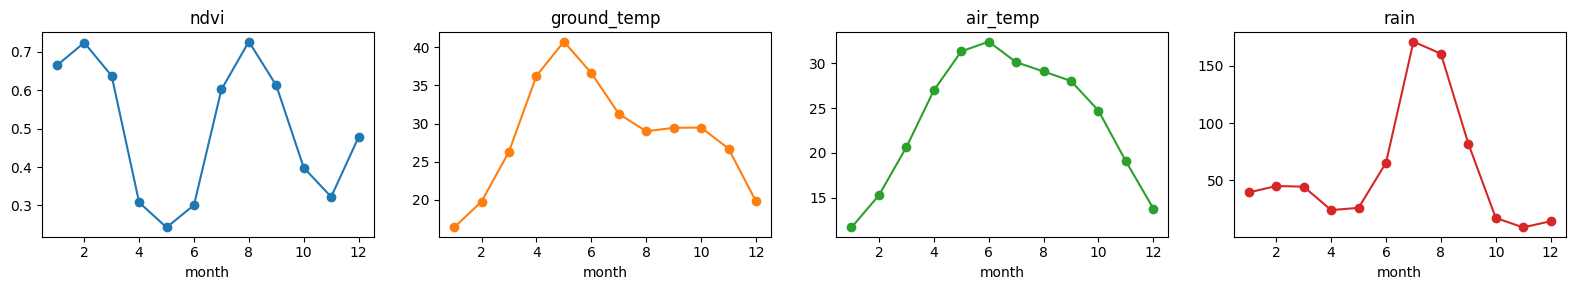

In [78]:
avg_year.plot(subplots=True, layout=(1, 4), figsize=(16, 3), marker="o", legend=False,
              title=list(avg_year.columns))
plt.tight_layout()
plt.show()

## What we see:
### Green (ndvi) peaks with wheat (Feb-Mar) and rice (Aug), heat peaks in May-June

### And rain is also heavier in month from (June-Sept)

## Now the actual question `are areas with tree cooler`

In [79]:
df["tree_minus_crop"] = df["ground_temp_trees"] - df["ground_temp_crops"]

In [80]:
gap = df.groupby("district")["tree_minus_crop"].mean().dropna().sort_values()

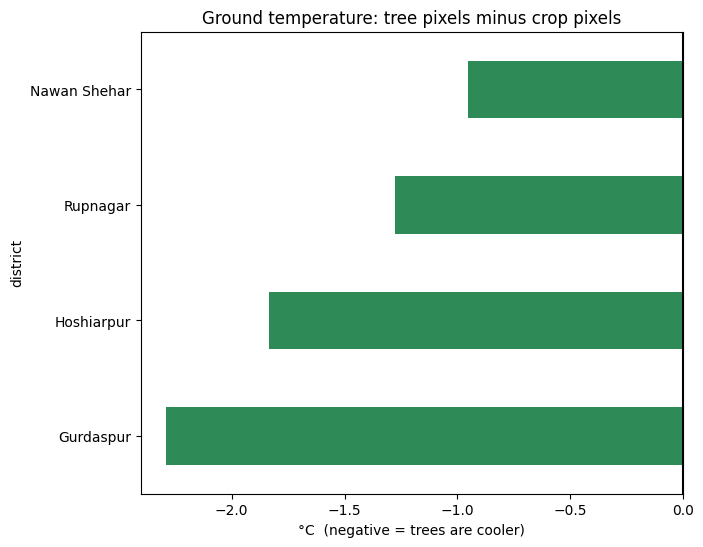

In [81]:
gap.plot.barh(figsize=(7, 6), color="seagreen")
plt.axvline(0, color="black")
plt.xlabel("°C  (negative = trees are cooler)")
plt.title("Ground temperature: tree pixels minus crop pixels")
plt.show()

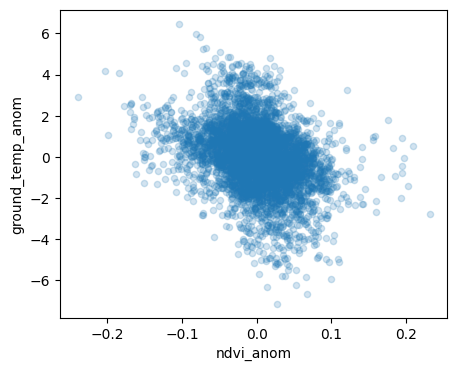

In [82]:
cols = ["ndvi", "ground_temp", "air_temp", "rain"]

normal = df.groupby(["district", df["month"].dt.month])[cols].transform("mean")
df[[f"{c}_anom" for c in cols]] = df[cols] - normal   # new columns: ndvi_anom, ground_temp_anom, ...

df.filter(like="_anom").corr().round(2)

df.plot.scatter("ndvi_anom", "ground_temp_anom", alpha=0.2, figsize=(5, 4))
plt.show()

In [90]:
for outcome in ["ground_temp_anom", "air_temp_anom"]:
    rows = df.dropna(subset=["ndvi_anom", "rain_anom", outcome])   # regression can't use empty cells
    X = rows[["ndvi_anom", "rain_anom"]]
    y = rows[outcome]

    model = LinearRegression().fit(X, y)          # learn a, b1, b2 from the data
    b1 = model.coef_[0]                           # coef_ = [b1, b2], same order as the X columns
    effect = b1 * 0.1                             # effect of +0.1 NDVI (a realistic change)
    r2 = model.score(X, y)                        # R²: share of the ups and downs explained (0 to 1)

    # p-value: sklearn doesn't calculate it, so we ask statsmodels the SAME question
    # with the SAME X and y. add_constant adds the "a" (intercept), which sklearn adds by itself.
    p = sm.OLS(y, sm.add_constant(X)).fit().pvalues["ndvi_anom"]

    print(f"{outcome}: +0.1 NDVI -> {effect:+.2f} °C  (p = {p:.3f}, R² = {r2:.2f})")

ground_temp_anom: +0.1 NDVI -> -1.00 °C  (p = 0.000, R² = 0.14)
air_temp_anom: +0.1 NDVI -> -0.39 °C  (p = 0.000, R² = 0.22)


# Conclusion

We used linear regression on monthly anomalies for all Punjab districts (2001–2026):

$$T' = a + b_1 \cdot \text{NDVI}' + b_2 \cdot \text{Rain}'$$

| Outcome | +0.1 NDVI | p-value | R² |
|---|---|---|---|
| Ground temperature | −1.00 °C | < 0.001 | 0.14 |
| Air temperature | −0.39 °C | < 0.001 | 0.22 |

Greener-than-usual months were cooler: about 1 °C on the ground and 0.4 °C in the air, even after taking rain into account. Both results are significant. But R² is low, so greenness explains only a small part of temperature changes.

This shows a link, not that greenness causes the cooling: irrigation can make fields both greener and cooler. Also, most green areas in Punjab are crop fields, not forests.